# Dodgers 2027 model and predictions

This notebook reviews the production forecast generated for the Dodgers 2027 roster-planning application. The selected models were refit using data through 2026 after the 2026 holdout evaluation. Because 2027 outcomes are not yet available, these are forecasts rather than validated results.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
forecast_path = ROOT / 'data' / 'forecasts' / 'player_forecasts_2027.csv'
dodgers_path = ROOT / 'data' / 'forecasts' / 'dodgers_forecast_shortlist_2027.csv'
forecast = pd.read_csv(forecast_path)
dodgers = pd.read_csv(dodgers_path)
print(f'All forecast rows: {len(forecast):,}')
print(f'Dodgers shortlist rows: {len(dodgers):,}')

All forecast rows: 407
Dodgers shortlist rows: 13


## Forecast audit

The production output should contain one row per player, no 2027 outcomes, and complete Statcast flags for the scoring population.

In [2]:
required = ['Name', 'season', 'forecast_season', 'pa_fg', 'predicted_eligibility_probability', 'predicted_wrc_plus', 'statcast_missing']
missing_columns = sorted(set(required) - set(forecast.columns))
assert not missing_columns, f'Missing columns: {missing_columns}'
assert forecast['Name'].notna().all()
available_ids = forecast['mlbam_id'].dropna()
assert not available_ids.duplicated().any(), 'Available MLBAM IDs must be unique'
assert (forecast['forecast_season'] == 2027).all()
print(f'Missing MLBAM IDs: {forecast["mlbam_id"].isna().sum()} / {len(forecast)}')
print(f'Statcast-missing rows: {forecast.statcast_missing.sum()} / {len(forecast)}')
forecast[required].head()

Missing MLBAM IDs: 40 / 407
Statcast-missing rows: 40 / 407


,Name,season,forecast_season,pa_fg,predicted_eligibility_probability,predicted_wrc_plus,statcast_missing
0,Ketel Marte,2026,2027,624,0.960228,113.622390,False
1,Vladimir Guerrero Jr.,2026,2027,609,0.937842,110.239237,False
2,Yordan Alvarez,2026,2027,692,0.994344,146.266302,False
3,Juan Soto,2026,2027,482,0.965733,134.548682,False
4,Pete Alonso,2026,2027,700,0.986740,133.661555,False


## Dodgers ranked shortlist

The table is ordered by the production shortlist ranking. Eligibility is the modeled probability of reaching at least 150 PA; predicted wRC+ is the conditional offensive forecast.

In [3]:
display_columns = [
    'Name', 'pa_fg', 'wrc_plus', 'predicted_wrc_plus',
    'predicted_eligibility_probability', 'predicted_wrc_plus_lift_vs_2026'
]
ranked = dodgers[display_columns].copy()
ranked.columns = ['Player', '2026 PA', '2026 wRC+', 'Predicted 2027 wRC+', 'Eligibility probability', 'Lift vs 2026']
ranked.round(1)

,Player,2026 PA,2026 wRC+,Predicted 2027 wRC+,Eligibility probability,Lift vs 2026
0,Shohei Ohtani,618,139.2,128.2,1.0,-11.0
1,Will Smith,276,117.9,112.8,0.8,-5.1
2,Freddie Freeman,657,119.9,112.6,1.0,-7.3
3,Max Muncy,561,128.9,112.0,1.0,-17.0
4,Mookie Betts,528,113.6,107.5,1.0,-6.1
5,Andy Pages,574,122.8,106.6,1.0,-16.1
6,Kyle Tucker,627,100.1,105.8,1.0,5.8
7,Teoscar Hernández,491,109.6,103.9,0.9,-5.7
8,Dalton Rushing,253,117.4,100.0,0.7,-17.4
9,Miguel Rojas,252,92.2,91.5,0.7,-0.7


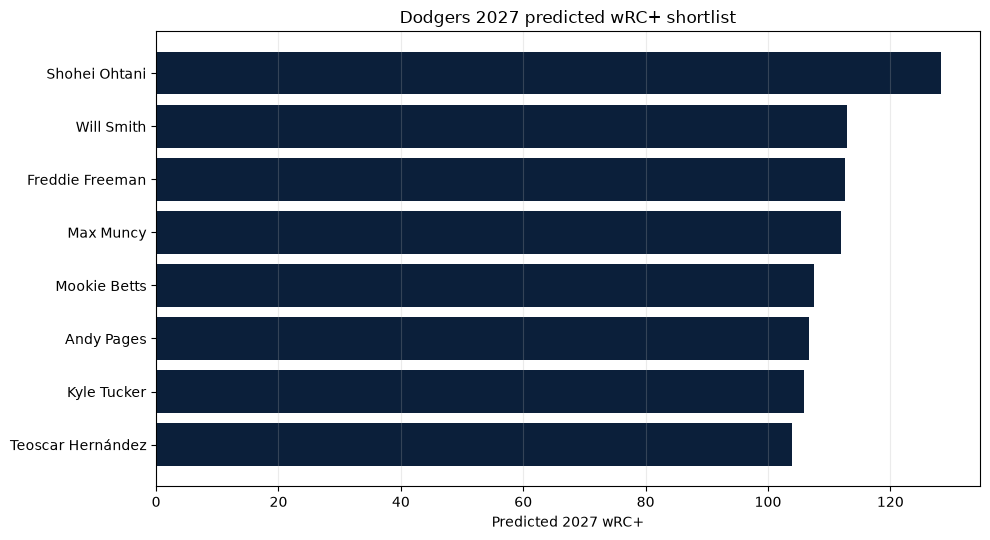

In [4]:
plot_df = ranked.sort_values('Predicted 2027 wRC+').tail(8)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(plot_df['Player'], plot_df['Predicted 2027 wRC+'], color='#0b1f3a')
ax.set_xlabel('Predicted 2027 wRC+')
ax.set_title('Dodgers 2027 predicted wRC+ shortlist')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Interpretation

Use the shortlist as a starting point for Dodgers baseball review. The model does not incorporate contracts, injuries, roster moves, defensive value, or expected lineup role, so those factors should be evaluated before any decision.